## Lab 4: FIR filters and envelopes

The goal of this lab is to connect the FIR filter ideas from the theory summary with the synthesis workflow from the previous labs. We will study two related ideas:

- a finite impulse response (FIR) filter as a weighted sum of past samples, and
- an envelope detector built from a rectifier followed by smoothing.

The theory summary on FIR filters introduces the key concepts behind convolution, impulse response, and the low-pass effect of a moving-average filter. The exercises below are designed to make those ideas concrete in both a toy example and in audio signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from util import load_audio, plot_spectrogram

### 1. FIR filters as weighted sums

An FIR filter computes the output as

$$
y[n] = \sum_{k=0}^{M} b_k x[n-k]
$$

where the coefficients $b_k$ define the filter. In the special case of a moving-average filter, all coefficients are equal to $1/(M+1)$ so the output is the average of $M+1$ input samples. This is exactly the operation implemented by convolution with an impulse response that is a short rectangular pulse.

A useful way to think about this is: the filter output at each instant is a local average of the input, so sharp changes get smoothed. That is why a moving-average filter is often used as a simple low-pass filter.

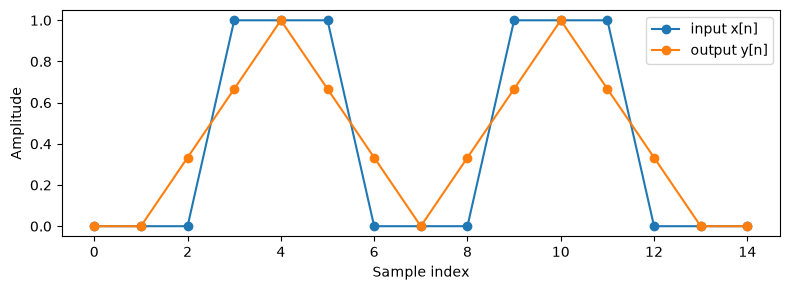

In [2]:
fs = 1
x = np.array([0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0], dtype=float)
b = np.array([1/3, 1/3, 1/3])
y = np.convolve(b, x, mode='same')

plt.figure(figsize=(8, 3))
plt.plot(x, 'o-', label='input x[n]')
plt.plot(y, 'o-', label='output y[n]')
plt.xlabel('Sample index')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

#### 1.1 Questions

1. Which parts of the signal become smoother after filtering?
    - The sharp transitions (the vertical step edges where the signal jumps between 0 and 1) become smoothed out into gradual slopes.
2. Why does the filtered output change more gradually than the original input?
    - Because each output sample is an average of neighboring input samples, which blurs abrupt jumps across several points.
3. What would happen to the smoothing effect if the filter used more coefficients?
    - The smoothing effect would increase, making step transitions flatter and wider, while further reducing sharp peaks.


#### 1.2 Implement an averaging filter
Complete the function below so that it applies an $N$-point moving-average filter with `np.convolve` and returns a result with the same length as the input. Try different values of $N$.

In [3]:
def averaging_filter(x, N):
    x = np.asarray(x, dtype=float)
    b = np.ones(N) / N
    return np.convolve(x, b, mode='same')

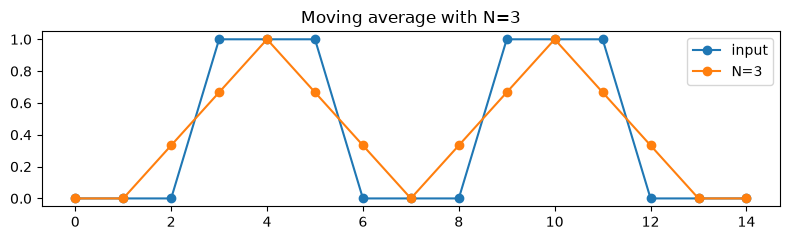

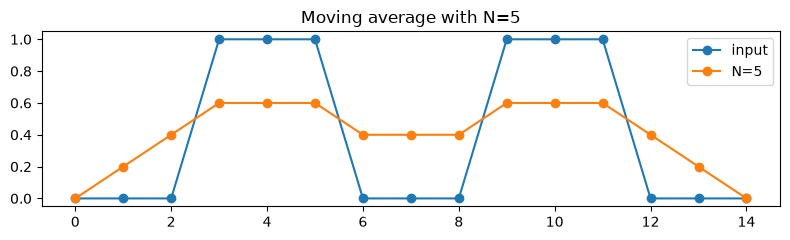

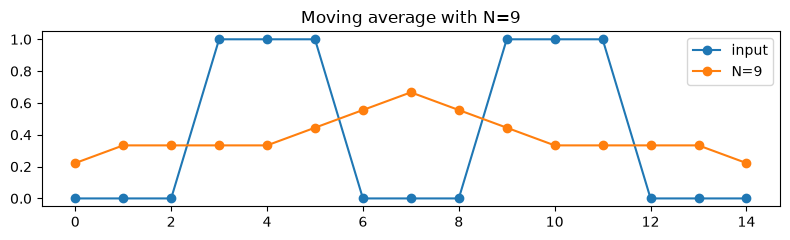

In [4]:
for N in [3, 5, 9]:
    y_N = averaging_filter(x, N)
    plt.figure(figsize=(8, 2.5))
    plt.plot(x, 'o-', label='input')
    plt.plot(y_N, 'o-', label=f'N={N}')
    plt.title(f'Moving average with N={N}')
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.3 Questions

1. What happens to the output when $N$ becomes larger?
   - Answer: As N increases, the output becomes smoother and flatter, blurring rapid variations over a wider time window.

2. Why does the filter behave like a low-pass filter?
   - Answer: Averaging attenuates fast, high-frequency oscillations while letting slow, low-frequency trends pass through.

3. Which frequencies are attenuated more strongly: low frequencies or high frequencies? [note: be careful because we are visualizing time-domain]
   - Answer: High frequencies are attenuated much more strongly because rapid changes get averaged out.

### 2. Envelope detection with rectification and smoothing
An detector uses two blocks:
1. a full-wave rectifier, implemented with `np.abs(x)`, and
2. a smoothing filter, implemented with the averaging filter from above.

The rectifier removes the sign of the signal, turning oscillations into a positive waveform. The averaging stage then removes the rapid oscillations and keeps the slower rise and fall of the envelope.

#### 2.1 Add envelope detector
Modify the following functions to try a few different values of $N$ and compare the resulting envelope.

In [5]:
def envelope(x, N):
    x = np.asarray(x, dtype=float)
    rectified = np.abs(x)
    return averaging_filter(rectified, N)

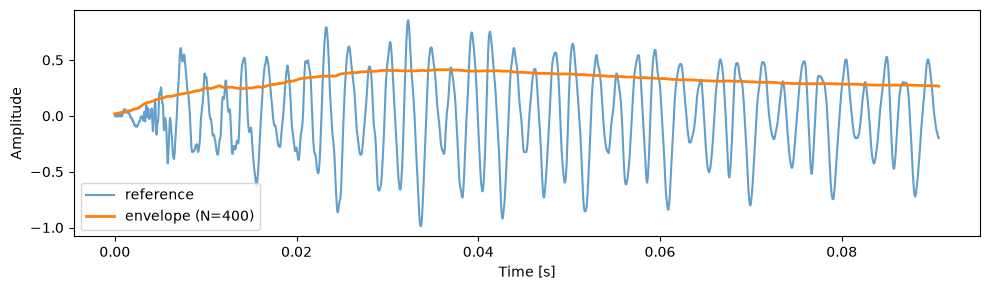

In [12]:
reference_audio, fs = load_audio('audio_lab1.wav')
t = np.arange(len(reference_audio)) / fs

N = 400
env = envelope(reference_audio, N)

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], reference_audio[:4000], alpha=0.7, label='reference')
plt.plot(t[:4000], env[:4000], linewidth=2, label=f'envelope (N={N})')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

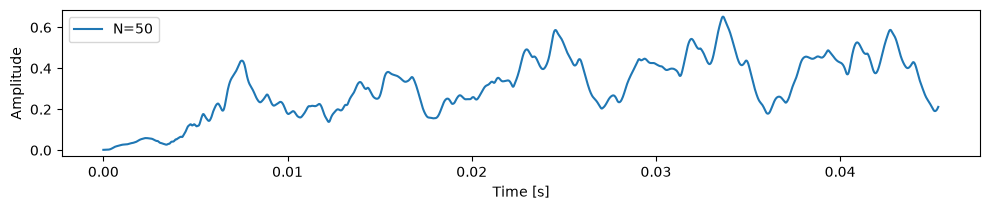

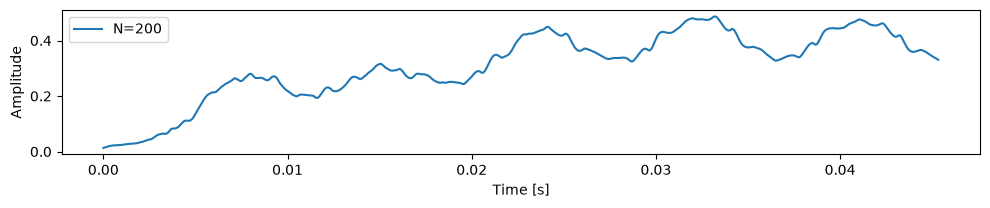

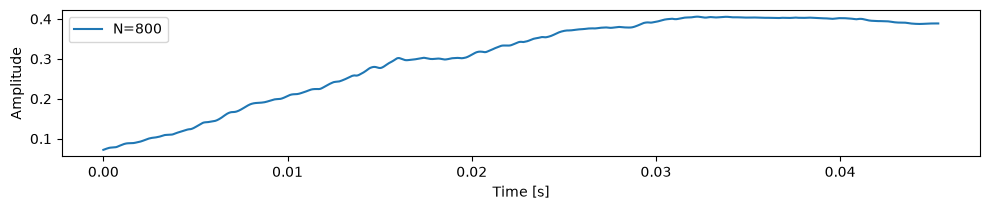

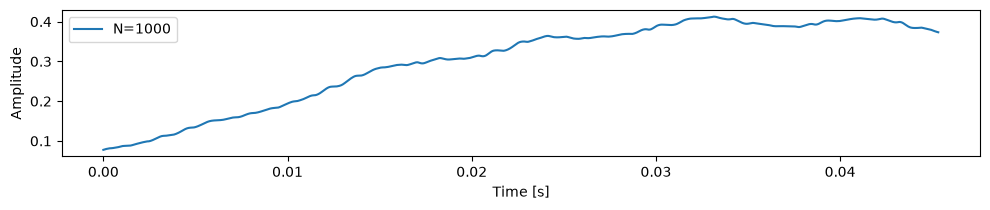

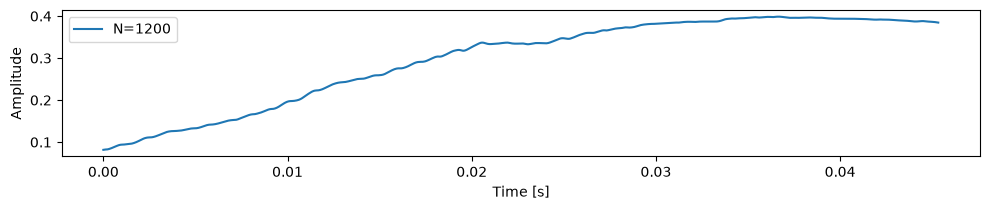

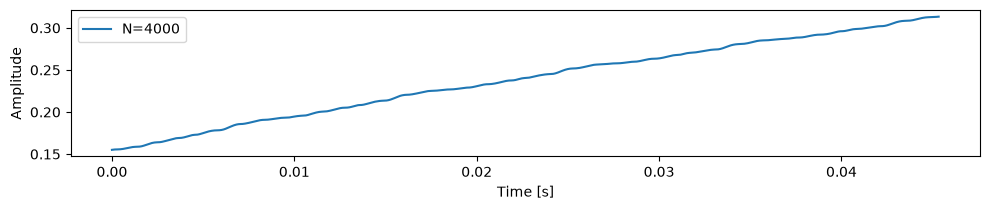

In [13]:
# Try a few filter sizes and inspect how the envelope changes
for N in [50, 200, 800, 1000, 1200, 4000]:
    env_N = envelope(reference_audio, N)
    plt.figure(figsize=(10, 2.2))
    plt.plot(t[:2000], env_N[:2000], label=f'N={N}')
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Try adding one or two more values of N here to see how the smoothing changes
# for example: [25, 100, 400, 1600]


#### 2.2 Questions

1. Why does the rectifier make the envelope easier to estimate?
   - Answer: Taking the absolute value (np.abs) flips all negative swings to positive, turning zero-crossing audio oscillations into a continuous positive contour.

2. What happens if $N$ is very small?
   - Answer: The envelope remains noisy and retains rapid ripple oscillations from individual waveform cycles instead of following the smooth overall contour.

3. What happens if $N$ is very large?
   - Answer: The envelope becomes overly smooth, flattening fast attack transients (like the initial pluck) and lagging behind sudden amplitude changes.

### 3. Apply the envelope to a synthesized sound

Now we combine the harmonic synthesis idea from Lab 3 with the envelope detector from this lab. The goal is to make the synthesized signal look and sound more like the reference by multiplying the harmonic signal by a slowly varying envelope. Add the amplitude weights obtained in Lab 3.

#### 3.1 Add envelope

Add your own amplitude weights in the code cell below and try at least two different values of the smoothing window $N$.
You can compare how the synthesized sound changes when the envelope is smoother or less smooth.


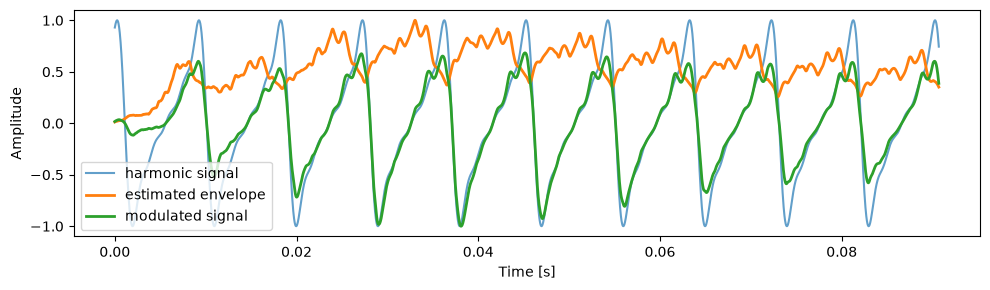

In [15]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

f0 = 111.1
phi = 0.8
# add your own amplitude weights
weights = [1.0, 0.60, 0.35, 0.20, 0.10]  
t = np.arange(len(reference_audio)) / fs

harmonic_signal = synthesize(f0, phi, weights, t)
harmonic_signal = harmonic_signal / np.max(np.abs(harmonic_signal))

# try different values of N
N = 100
envelope_signal = envelope(reference_audio, N)
envelope_signal = envelope_signal / np.max(np.abs(envelope_signal))

modulated_signal = harmonic_signal * envelope_signal
modulated_signal = modulated_signal / np.max(np.abs(modulated_signal))

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], harmonic_signal[:4000], alpha=0.7, label='harmonic signal')
plt.plot(t[:4000], envelope_signal[:4000], linewidth=2, label='estimated envelope')
plt.plot(t[:4000], modulated_signal[:4000], linewidth=2, label='modulated signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

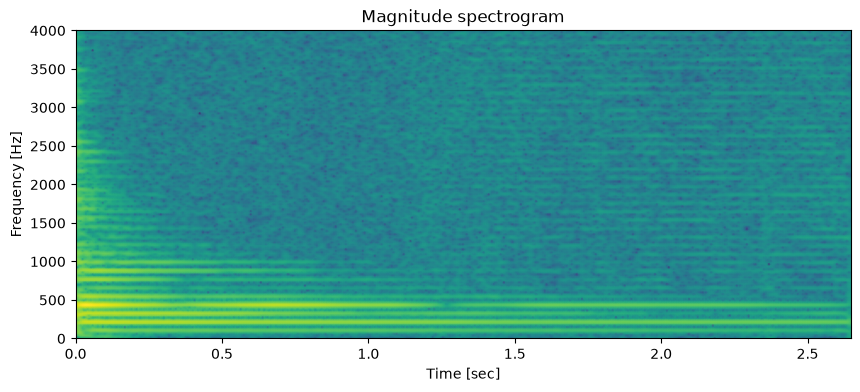

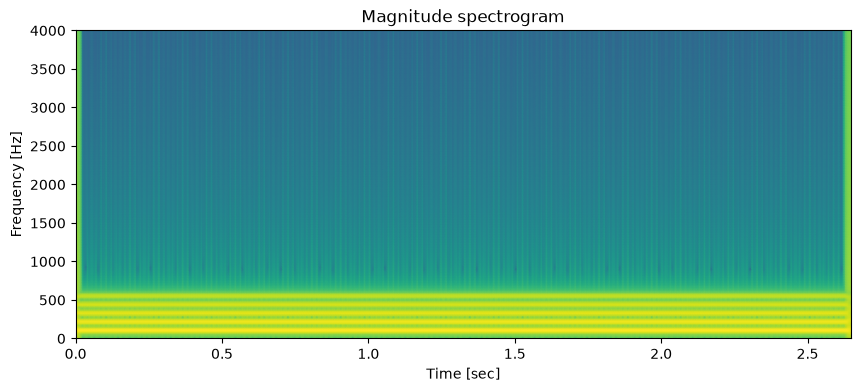

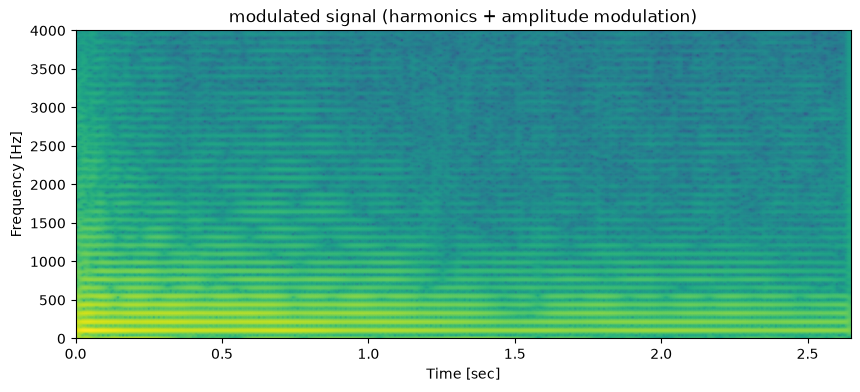

In [16]:
# The envelope introduces amplitude modulation, so the modulated signal will show more structure than a pure harmonic tone.
ax1 = plot_spectrogram(reference_audio, sr=fs, N=2048, H=256)
ax2 = plot_spectrogram(harmonic_signal, sr=fs, N=2048, H=256)
ax3 = plot_spectrogram(modulated_signal, sr=fs, N=2048, H=256)

ax1.set_ylim([0, 4000])
ax2.set_ylim([0, 4000])
ax3.set_ylim([0, 4000])
ax3.set_title('modulated signal (harmonics + amplitude modulation)')
plt.show()


In [17]:
from IPython.display import Audio, display

print("Reference sound")
display(Audio(reference_audio, rate=fs))

print("Harmonic sound")
display(Audio(harmonic_signal, rate=fs))

print("Modulated sound")
display(Audio(modulated_signal, rate=fs))


Reference sound


Harmonic sound


Modulated sound


#### 3.2 Questions

1. How does the envelope change the amplitude of the sound over time?
   - Answer: The envelope shapes the static harmonic tone with a realistic attack and exponential decay, causing the sound to start loudly and fade out naturally like a real string pluck.

2. What is the main difference between the spectrogram of the pure harmonic signal and the spectrogram of the modulated signal?
   - Answer: The pure harmonic spectrogram shows static lines that remain bright forever, whereas the modulated spectrogram shows horizontal harmonic lines that dim and fade over time.

3. Why does the modulated signal show more structure than the purely harmonic signal?
   - Answer: Because amplitude modulation spreads energy across time according to the note's natural temporal evolution (pluck attack and gradual decay).

4. Why is the smoothing stage important for creating a realistic amplitude envelope?
   - Answer: Without smoothing, individual wave cycle oscillations would distort the signal. Smoothing extracts only the slow overall amplitude volume curve needed to shape the sound realistically.